# Lab 2: Forecasting Classical Time Series

Student: Lopatenko George (334771)  
Course: Machine Learning for Time Series (TSML)


## 0. Setup


In [1]:
import sys
import subprocess
import importlib.util
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
LAB_DIR = Path.cwd()
if not (LAB_DIR / "M2_Lopatenko.ipynb").exists():
    for candidate in [LAB_DIR / "tsml" / "lab-2", LAB_DIR.parent / "tsml" / "lab-2", Path("/content")]:
        if (candidate / "M2_Lopatenko.ipynb").exists():
            LAB_DIR = candidate
            break

REQUIREMENTS = [
    "numpy",
    "pandas",
    "scipy",
    "statsmodels",
    "plotly",
    "kaleido",
    "nbformat",
    "nbclient",
    "prettytable",
]
missing = [package for package in REQUIREMENTS if importlib.util.find_spec(package) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

{"lab_dir": str(LAB_DIR), "in_colab": IN_COLAB, "installed_now": missing}


{'lab_dir': '/Users/lopatenko/Desktop/itmo/itmo-ml-2025/tsml/lab-2',
 'in_colab': False,
 'installed_now': []}

In [2]:
import json
import warnings
from dataclasses import dataclass
from itertools import product
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from IPython.display import Image, Markdown, display
from plotly.subplots import make_subplots
from prettytable import PrettyTable
from scipy.optimize import minimize
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing

warnings.filterwarnings("ignore")

SEED = 42
HORIZONS = (1, 7, 14)
N_SPLITS = 10
FIG_WIDTH, FIG_SCALE = 1400, 3

np.random.seed(SEED)
pio.templates.default = "plotly_white"
pio.renderers.default = "notebook_connected"

DATA_DIR = LAB_DIR / "data"
FIGURES_DIR = LAB_DIR / "figures"
DATA_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def show_table(frame: pd.DataFrame, caption: str, precision: int = 3) -> None:
    def format_value(value) -> str:
        if pd.isna(value):
            return "—"
        if isinstance(value, (float, np.floating)):
            return f"{value:.{precision}f}"
        return str(value)

    table = PrettyTable()
    table.title = caption
    table.field_names = [str(column) for column in frame.columns]
    table.align = "l"
    for field in table.field_names:
        table.max_width[field] = 32
    for row in frame.itertuples(index=False, name=None):
        table.add_row([format_value(value) for value in row])
    print(table)

{"lab_dir": str(LAB_DIR), "data": str(DATA_DIR), "figures": str(FIGURES_DIR)}


{'lab_dir': '/Users/lopatenko/Desktop/itmo/itmo-ml-2025/tsml/lab-2',
 'data': '/Users/lopatenko/Desktop/itmo/itmo-ml-2025/tsml/lab-2/data',
 'figures': '/Users/lopatenko/Desktop/itmo/itmo-ml-2025/tsml/lab-2/figures'}

## 1. Data

The same three open univariate series as in Lab 1 are used:

- **EU hourly electricity load** (Darts `energy_dataset`) — clear daily/weekly periods;
- **ECG** (TensorFlow ECG anomaly CSV) — six concatenated normal beats;
- **SPY adjusted close** (Yahoo chart API) — a Brownian-like financial level series.


In [3]:
@dataclass(frozen=True)
class SeriesBundle:
    name: str
    domain: str
    kind: str
    source: str
    values: np.ndarray
    index: Optional[pd.Index] = None
    seasonal_period: Optional[int] = None


ENERGY_URL = "https://raw.githubusercontent.com/unit8co/darts/master/datasets/energy_dataset.csv"
ECG_URL = "https://storage.googleapis.com/download.tensorflow.org/data/ecg.csv"


def clamp_length(x: np.ndarray, n_min: int = 500, n_max: int = 1000) -> np.ndarray:
    x = np.asarray(x, dtype=float).ravel()
    x = x[np.isfinite(x)]
    if len(x) > n_max:
        x = x[-n_max:]
    if len(x) < n_min:
        raise ValueError(f"series too short: {len(x)} < {n_min}")
    return x


def _download(url: str, dest: Path) -> Path:
    import urllib.request

    if dest.exists() and dest.stat().st_size > 0:
        return dest
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=120) as response, dest.open("wb") as out:
        out.write(response.read())
    return dest


def load_energy_load(n: int = 720) -> Tuple[np.ndarray, pd.DatetimeIndex]:
    path = _download(ENERGY_URL, DATA_DIR / "energy_dataset.csv")
    df = pd.read_csv(path, parse_dates=["time"])
    series = df[["time", "total load actual"]].dropna().iloc[-n:]
    values = clamp_length(series["total load actual"].to_numpy(), n_min=min(n, 500), n_max=n)
    index = pd.DatetimeIndex(series["time"].iloc[-len(values):].to_numpy())
    return values, index


def load_ecg_series(n_beats: int = 6, label: float = 1.0) -> np.ndarray:
    # TF ECG: 140 samples/beat + label; label 1 is normal rhythm in the TF tutorial.
    path = _download(ECG_URL, DATA_DIR / "ecg.csv")
    df = pd.read_csv(path, header=None)
    beats = df[df.iloc[:, -1] == label].iloc[:n_beats, :-1].to_numpy(dtype=float)
    return clamp_length(beats.ravel())


def load_finance_close(ticker: str = "SPY", n: int = 750) -> Tuple[np.ndarray, pd.DatetimeIndex]:
    import urllib.request

    cache = DATA_DIR / f"{ticker}_AdjClose.csv"
    if cache.exists() and cache.stat().st_size > 0:
        df = pd.read_csv(cache, parse_dates=["Date"])
    else:
        url = f"https://query1.finance.yahoo.com/v8/finance/chart/{ticker}?interval=1d&range=5y"
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req, timeout=60) as response:
            payload = json.loads(response.read().decode("utf-8"))
        result = payload["chart"]["result"][0]
        df = pd.DataFrame({
            "Date": pd.to_datetime(result["timestamp"], unit="s"),
            "Close": result["indicators"]["adjclose"][0]["adjclose"],
        }).dropna()
        df.to_csv(cache, index=False)
    df = df.dropna().iloc[-n:]
    values = clamp_length(df["Close"].to_numpy(), n_min=min(n, 500), n_max=n)
    return values, pd.DatetimeIndex(df["Date"].iloc[-len(values):])


def make_series() -> List[SeriesBundle]:
    energy, energy_index = load_energy_load(n=720)
    ecg = load_ecg_series(n_beats=6, label=1.0)
    spy, spy_index = load_finance_close("SPY", n=750)
    return [
        SeriesBundle("EU_Hourly_Load", "energy", "periodic", "Darts energy_dataset (total load actual)", energy, energy_index, 24),
        SeriesBundle("ECG_TF_Normal", "cardiogram", "quasi-periodic", "TensorFlow ECG anomaly dataset (concatenated normal beats)", ecg, None, 140),
        SeriesBundle("SPY_AdjClose", "finance", "brownian", "Yahoo Finance chart API (adj close)", spy, spy_index, None),
    ]


SERIES = make_series()
series_overview = pd.DataFrame([
    {
        "name": s.name,
        "domain": s.domain,
        "kind": s.kind,
        "source": s.source,
        "n": len(s.values),
        "seasonal_period": s.seasonal_period,
        "mean": np.mean(s.values),
        "std": np.std(s.values),
        "min": np.min(s.values),
        "max": np.max(s.values),
    }
    for s in SERIES
])
show_table(series_overview, "Series overview")


+--------------------------------------------------------------------------------------------------------------------------------------------------------+
|                                                                    Series overview                                                                     |
+----------------+------------+----------------+----------------------------------+-----+-----------------+-----------+----------+-----------+-----------+
| name           | domain     | kind           | source                           | n   | seasonal_period | mean      | std      | min       | max       |
+----------------+------------+----------------+----------------------------------+-----+-----------------+-----------+----------+-----------+-----------+
| EU_Hourly_Load | energy     | periodic       | Darts energy_dataset (total load | 720 | 24.000          | 28781.829 | 4890.555 | 18179.000 | 38783.000 |
|                |            |                | actual)              

### Series context

#### EU_Hourly_Load (energy, periodic)

- **What:** ENTSO-E style hourly electricity demand (MW) for a European system.
- **Known structure:** Strong 24 h and 168 h cycles arise from human activity, industry, weather and calendar effects. The daily period $s=24$ is used because it was the dominant FFT period in Lab 1 and it is well represented in every training window.
- **Forecasting expectation:** strong autocorrelation and repeated daily shape should help AR and seasonal Holt–Winters models.
- **Refs:** Hong & Fan (2016); Hippert, Pedreira & Souza (2001).

#### ECG_TF_Normal (cardiogram, quasi-periodic)

- **What:** Normal ECG beats from the TensorFlow ECG anomaly dataset (140 samples per beat), with six beats concatenated into one quasi-periodic trace.
- **Known structure:** QRS morphology repeats every cardiac cycle; healthy variability makes the repetitions imperfect. The known beat length gives $s=140$.
- **Forecasting expectation:** a long AR memory or seasonal smoothing can reuse beat morphology, while errors may grow when successive beats differ.
- **Refs:** Bandt & Pompe (2002); Richman & Moorman (2000); TensorFlow ECG tutorial dataset.

#### SPY_AdjClose (finance, Brownian-like)

- **What:** S&P 500 ETF adjusted daily close, a broad equity-index level.
- **Known structure:** price levels are close to a random walk; returns have weak linear autocorrelation and changing volatility. No stable seasonal period was found in Lab 1, so Holt–Winters is fitted without a seasonal component.
- **Forecasting expectation:** persistence makes one-step level forecasts reasonable, but model differences should be small and uncertainty should increase with horizon.
- **Refs:** Fama (1970); Mandelbrot (1963); Cont (2001).


## 2. Models, metric and validation design

Three model families are compared.

**Autoregression AR($p$)**

$$
y_t=c+\beta t+\sum_{i=1}^{p}\phi_i y_{t-i}+\varepsilon_t.
$$

Candidate lag orders are tied to each signal: short lags plus daily lags for load, within-beat and full-beat lags for ECG, and short lags for SPY.

**ARIMA($p,d,q$)**

$$
\Phi(B)(1-B)^d y_t=\Theta(B)\varepsilon_t.
$$

A compact grid $p\in\{0,1,2,3\}$, $d\in\{0,1\}$, $q\in\{0,1,2\}$ is searched. This covers stationary ARMA dynamics and one differencing step appropriate for a stochastic trend without overfitting the short series.

**Holt–Winters / exponential smoothing**

Additive trend and additive seasonality are considered because the seasonal amplitude does not grow proportionally with the level and ECG contains negative values. Damped trend is also tested. The domain-supported periods are 24 for load and 140 for ECG; SPY has no stable seasonal period and therefore uses the non-seasonal Holt variants.

Each family has two implementations:

- **statsmodels:** `AutoReg`, `ARIMA` and `ExponentialSmoothing`;
- **custom:** AR coefficients are estimated by ordinary least squares, ARIMA uses explicit differencing plus conditional-sum-of-squares ARMA residuals, and Holt–Winters uses the additive level/trend/seasonal recursions. The custom ARIMA and Holt–Winters objective functions are optimized with SciPy; no statsmodels estimator is called by the custom path.

Every structural candidate is fitted only to data before a held-out 14-point validation tail. Its statsmodels score is the mean normalized MAE at horizons 1, 7 and 14. This scale-safe selection score avoids the singularity of percentage errors around zero in ECG. The selected structural hyperparameters are then **fixed and shared by both implementations** for all final tests. This keeps the comparison focused on implementation and parameter estimation rather than different model orders.

Final evaluation uses expanding training windows. For each horizon $h\in\{1,7,14\}$, the last $10h$ observations are divided into ten adjacent, non-overlapping blocks of length $h$. At origin $o_j=n-10h+jh$, a model sees only $y_1,\ldots,y_{o_j}$ and predicts the next $h$ observations.

$$
\operatorname{MAPE}=\frac{100\%}{h}\sum_{i=1}^{h}\left|\frac{y_{o+i}-\hat y_{o+i}}{y_{o+i}}\right|.
$$

Exact zeros are excluded from this conventional definition. MAPE remains unstable near zero, so ECG percentages must be interpreted with that limitation in mind.


In [4]:
def mape(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    mask = np.abs(y_true) > 1e-8
    if not np.any(mask):
        return np.nan
    return float(100 * np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])))


def normalized_mae(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    scale = max(float(np.mean(np.abs(y_true))), 1e-8)
    return float(np.mean(np.abs(np.asarray(y_true) - np.asarray(y_pred))) / scale)


def custom_ar_forecast(train: np.ndarray, horizon: int, lags: int) -> np.ndarray:
    # AR(p) with constant and time trend, estimated by NumPy OLS.
    y = np.asarray(train, dtype=float)
    t = np.arange(lags, len(y))
    X = np.column_stack([
        np.ones(len(t)),
        t,
        *[y[t - lag] for lag in range(1, lags + 1)],
    ])
    coefficients = np.linalg.lstsq(X, y[lags:], rcond=None)[0]
    history = y.tolist()
    for step in range(horizon):
        row = [1.0, len(y) + step] + [history[-lag] for lag in range(1, lags + 1)]
        history.append(float(np.dot(row, coefficients)))
    return np.asarray(history[-horizon:])


def _arma_errors(parameters: np.ndarray, values: np.ndarray, p: int, q: int) -> np.ndarray:
    intercept = parameters[0]
    ar = parameters[1:1 + p]
    ma = parameters[1 + p:]
    errors = np.zeros(len(values))
    for t in range(len(values)):
        prediction = intercept
        prediction += sum(ar[i - 1] * values[t - i] for i in range(1, p + 1) if t >= i)
        prediction += sum(ma[j - 1] * errors[t - j] for j in range(1, q + 1) if t >= j)
        errors[t] = values[t] - prediction
    return errors


def custom_arima_forecast(train: np.ndarray, horizon: int, order: Tuple[int, int, int]) -> np.ndarray:
    # ARIMA(p,d,q) estimated by conditional sum of squared ARMA errors.
    p, d, q = order
    if not isinstance(d, (int, np.integer)) or d < 0:
        raise ValueError("d must be a non-negative integer")

    original = np.asarray(train, dtype=float)
    if len(original) - d <= max(p, q) + 1:
        raise ValueError("not enough observations for the requested ARIMA order")
    values = np.diff(original, n=d) if d else original.copy()
    scale = max(float(np.std(values)), 1e-8)
    values = values / scale

    initial = np.zeros(1 + p + q)
    initial[0] = float(np.mean(values))
    if p:
        t = np.arange(p, len(values))
        X = np.column_stack([np.ones(len(t)), *[values[t - lag] for lag in range(1, p + 1)]])
        initial[:1 + p] = np.linalg.lstsq(X, values[p:], rcond=None)[0]

    start = max(p, q)

    def objective(parameters: np.ndarray) -> float:
        residuals = _arma_errors(parameters, values, p, q)[start:]
        return float(np.mean(residuals**2))

    bounds = [(None, None)] + [(-0.99, 0.99)] * (p + q)
    optimized = minimize(objective, initial, method="L-BFGS-B", bounds=bounds, options={"maxiter": 400})
    parameters = optimized.x if np.all(np.isfinite(optimized.x)) else initial

    intercept = parameters[0]
    ar = parameters[1:1 + p]
    ma = parameters[1 + p:]
    history = values.tolist()
    error_history = _arma_errors(parameters, values, p, q).tolist()
    differences = []
    for _ in range(horizon):
        prediction = intercept
        prediction += sum(ar[i - 1] * history[-i] for i in range(1, p + 1))
        prediction += sum(ma[j - 1] * error_history[-j] for j in range(1, q + 1))
        history.append(float(prediction))
        error_history.append(0.0)
        differences.append(float(prediction * scale))

    differences = np.asarray(differences)
    if d == 0:
        return differences

    # Integrate the predicted d-th differences one order at a time.
    histories = [np.diff(original, n=order).tolist() for order in range(d + 1)]
    forecast = []
    for highest_difference in differences:
        histories[d].append(float(highest_difference))
        for order in range(d - 1, -1, -1):
            histories[order].append(histories[order][-1] + histories[order + 1][-1])
        forecast.append(histories[0][-1])
    return np.asarray(forecast)


def _holt_winters_states(values: np.ndarray, config: dict, smoothing: np.ndarray):
    trend_enabled = config["trend"] == "add"
    seasonal_enabled = config["seasonal"] == "add"
    damped = bool(config["damped_trend"])
    period = config["seasonal_periods"] or 1

    position = 0
    alpha = smoothing[position]
    position += 1
    beta = smoothing[position] if trend_enabled else 0.0
    position += int(trend_enabled)
    gamma = smoothing[position] if seasonal_enabled else 0.0
    position += int(seasonal_enabled)
    phi = smoothing[position] if damped else 1.0

    if seasonal_enabled:
        level = float(np.mean(values[:period]))
        seasonals = values[:period].copy() - level
        trend = float(np.mean((values[period:2 * period] - values[:period]) / period)) if trend_enabled else 0.0
        start = period
    else:
        level = float(values[0])
        seasonals = np.zeros(1)
        trend = float(np.mean(np.diff(values[:min(10, len(values))]))) if trend_enabled else 0.0
        start = 1

    errors = []
    for t in range(start, len(values)):
        seasonal = seasonals[t % period] if seasonal_enabled else 0.0
        base = level + (phi * trend if trend_enabled else 0.0)
        errors.append(values[t] - base - seasonal)
        new_level = alpha * (values[t] - seasonal) + (1 - alpha) * base
        if trend_enabled:
            new_trend = beta * (new_level - level) + (1 - beta) * phi * trend
        if seasonal_enabled:
            seasonals[t % period] = gamma * (values[t] - new_level) + (1 - gamma) * seasonal
        level = new_level
        if trend_enabled:
            trend = new_trend
    return level, trend, seasonals, phi, np.asarray(errors)


def custom_holt_winters_forecast(train: np.ndarray, horizon: int, config: dict) -> np.ndarray:
    # Additive Holt-Winters recursions with smoothing parameters fitted by SSE.
    y = np.asarray(train, dtype=float)
    center = float(np.mean(y))
    scale = max(float(np.std(y)), 1e-8)
    values = (y - center) / scale

    trend_enabled = config["trend"] == "add"
    seasonal_enabled = config["seasonal"] == "add"
    damped = bool(config["damped_trend"])
    initial = [0.2] + ([0.05] if trend_enabled else []) + ([0.05] if seasonal_enabled else []) + ([0.98] if damped else [])
    bounds = [(0.001, 0.999)] * (1 + int(trend_enabled) + int(seasonal_enabled))
    if damped:
        bounds.append((0.8, 0.999))

    def objective(smoothing: np.ndarray) -> float:
        errors = _holt_winters_states(values, config, smoothing)[-1]
        return float(np.mean(errors**2))

    optimized = minimize(objective, initial, method="L-BFGS-B", bounds=bounds, options={"maxiter": 300})
    smoothing = optimized.x if np.all(np.isfinite(optimized.x)) else np.asarray(initial)
    level, trend, seasonals, phi, _ = _holt_winters_states(values, config, smoothing)
    period = config["seasonal_periods"] or 1

    forecast = []
    for step in range(1, horizon + 1):
        trend_effect = trend * sum(phi**power for power in range(1, step + 1)) if trend_enabled else 0.0
        seasonal = seasonals[(len(values) + step - 1) % period] if seasonal_enabled else 0.0
        forecast.append(level + trend_effect + seasonal)
    return center + scale * np.asarray(forecast)


def fit_forecast(family: str, implementation: str, train: np.ndarray, horizon: int, params: dict) -> np.ndarray:
    if implementation == "custom":
        if family == "AR":
            return custom_ar_forecast(train, horizon, params["lags"])
        if family == "ARIMA":
            return custom_arima_forecast(train, horizon, tuple(params["order"]))
        return custom_holt_winters_forecast(train, horizon, params)

    if family == "AR":
        fit = AutoReg(train, lags=params["lags"], trend="ct").fit()
        return np.asarray(fit.predict(len(train), len(train) + horizon - 1), dtype=float)
    if family == "ARIMA":
        order = tuple(params["order"])
        trend = "c" if order[1] == 0 else "t" if order[1] == 1 else "n"
        fit = ARIMA(train, order=order, trend=trend, enforce_stationarity=False, enforce_invertibility=False).fit()
        return np.asarray(fit.forecast(horizon), dtype=float)

    fit = ExponentialSmoothing(
        train,
        trend=params["trend"],
        damped_trend=params["damped_trend"],
        seasonal=params["seasonal"],
        seasonal_periods=params["seasonal_periods"],
        initialization_method="estimated",
    ).fit(optimized=True, use_brute=False)
    return np.asarray(fit.forecast(horizon), dtype=float)


_polynomial = np.arange(1, 80, dtype=float) ** 4
for _d in range(4):
    _forecast = custom_arima_forecast(_polynomial, 3, (1, _d, 0))
    assert _forecast.shape == (3,) and np.isfinite(_forecast).all()
del _polynomial, _forecast, _d


def candidate_grid(bundle: SeriesBundle, family: str) -> List[dict]:
    if family == "AR":
        lags = {
            "EU_Hourly_Load": [1, 2, 3, 6, 12, 24, 48, 168],
            "ECG_TF_Normal": [1, 2, 3, 5, 10, 20, 70, 140],
            "SPY_AdjClose": [1, 2, 3, 5, 10, 20],
        }[bundle.name]
        return [{"lags": lag} for lag in lags]

    if family == "ARIMA":
        return [
            {"order": (p, d, q)}
            for p, d, q in product(range(4), range(2), range(3))
            if (p, d, q) != (0, 0, 0)
        ]

    period = bundle.seasonal_period
    candidates = [
        {"trend": None, "damped_trend": False, "seasonal": None, "seasonal_periods": None},
        {"trend": "add", "damped_trend": False, "seasonal": None, "seasonal_periods": None},
        {"trend": "add", "damped_trend": True, "seasonal": None, "seasonal_periods": None},
    ]
    if period is not None:
        candidates += [
            {"trend": None, "damped_trend": False, "seasonal": "add", "seasonal_periods": period},
            {"trend": "add", "damped_trend": False, "seasonal": "add", "seasonal_periods": period},
            {"trend": "add", "damped_trend": True, "seasonal": "add", "seasonal_periods": period},
        ]
    return candidates


def select_params(bundle: SeriesBundle, family: str) -> Tuple[dict, float, int]:
    x = bundle.values
    evaluation_start = len(x) - N_SPLITS * max(HORIZONS)
    validation_end = evaluation_start
    validation_start = validation_end - max(HORIZONS)
    train, valid = x[:validation_start], x[validation_start:validation_end]
    scored = []
    for params in candidate_grid(bundle, family):
        try:
            pred = fit_forecast(family, "statsmodels", train, max(HORIZONS), params)
            score = np.mean([
                normalized_mae(valid[:h], pred[:h])
                for h in HORIZONS
            ])
            if np.isfinite(score):
                scored.append((float(score), params))
        except (ValueError, np.linalg.LinAlgError):
            continue
    if not scored:
        raise RuntimeError(f"no valid {family} configuration for {bundle.name}")
    score, params = min(scored, key=lambda item: item[0])
    return params, score, validation_start


## 3. Hyperparameter selection

The table below records the empirical choice rather than hiding it inside the final evaluation. `validation_end` is strictly earlier than the first final test origin. Each selected row is reused unchanged by statsmodels and the custom implementation.


In [5]:
FAMILIES = ("AR", "ARIMA", "Holt-Winters")
IMPLEMENTATIONS = ("statsmodels", "custom")
SELECTED: Dict[Tuple[str, str], dict] = {}
selection_rows = []

for bundle in SERIES:
    for family in FAMILIES:
        params, score, validation_start = select_params(bundle, family)
        SELECTED[(bundle.name, family)] = params
        selection_rows.append({
            "series": bundle.name,
            "family": family,
            "selected_parameters": json.dumps(params),
            "validation_score": score,
            "used_by": "statsmodels + custom",
            "validation_start": validation_start,
            "validation_end": len(bundle.values) - N_SPLITS * max(HORIZONS),
            "first_test_origin": len(bundle.values) - N_SPLITS * max(HORIZONS),
        })

selection_table = pd.DataFrame(selection_rows)
selection_table.to_csv(LAB_DIR / "selected_hyperparameters.csv", index=False)
show_table(selection_table, "Selected structural hyperparameters")


+--------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|                                                                Selected structural hyperparameters                                                                 |
+----------------+--------------+----------------------------------+------------------+----------------------+------------------+----------------+-------------------+
| series         | family       | selected_parameters              | validation_score | used_by              | validation_start | validation_end | first_test_origin |
+----------------+--------------+----------------------------------+------------------+----------------------+------------------+----------------+-------------------+
| EU_Hourly_Load | AR           | {"lags": 48}                     | 0.036            | statsmodels + custom | 566              | 580            | 580               

### Reading the selected parameters

- For **AR**, `lags` controls how much recent history enters the linear regression. A daily or beat-scale lag is useful only if the validation data confirm that the repeated shape is stable.
- For **ARIMA**, `d=1` indicates that changes are more stable than levels; `p` and `q` capture short autoregressive and shock-memory effects.
- For **Holt–Winters**, `trend="add"` adds a linear local trend, `damped_trend=true` prevents indefinite extrapolation, and `seasonal="add"` reuses the fixed-amplitude domain period.


## 4. Repeated out-of-sample evaluation


In [6]:
def test_origins(n: int, horizon: int, n_splits: int = N_SPLITS) -> List[int]:
    first = n - n_splits * horizon
    return [first + split * horizon for split in range(n_splits)]


rows = []
FORECASTS = {}

for bundle in SERIES:
    x = bundle.values
    for family in FAMILIES:
        params = SELECTED[(bundle.name, family)]
        for implementation in IMPLEMENTATIONS:
            for horizon in HORIZONS:
                for split, origin in enumerate(test_origins(len(x), horizon), start=1):
                    actual = x[origin:origin + horizon]
                    forecast = fit_forecast(family, implementation, x[:origin], horizon, params)
                    rows.append({
                        "series": bundle.name,
                        "family": family,
                        "implementation": implementation,
                        "horizon": horizon,
                        "split": split,
                        "origin": origin,
                        "mape": mape(actual, forecast),
                    })
                    FORECASTS[(bundle.name, family, implementation, horizon, split)] = (actual, forecast, origin)

results = pd.DataFrame(rows)
assert len(results) == len(SERIES) * len(FAMILIES) * len(IMPLEMENTATIONS) * len(HORIZONS) * N_SPLITS
assert results["mape"].notna().all()

agreement_rows = []
for bundle in SERIES:
    for family in FAMILIES:
        for horizon in HORIZONS:
            for split in range(1, N_SPLITS + 1):
                _, framework_forecast, _ = FORECASTS[(bundle.name, family, "statsmodels", horizon, split)]
                _, custom_forecast, _ = FORECASTS[(bundle.name, family, "custom", horizon, split)]
                absolute_difference = np.abs(custom_forecast - framework_forecast)
                scale = max(float(np.mean(np.abs(framework_forecast))), 1e-8)
                agreement_rows.append({
                    "series": bundle.name,
                    "family": family,
                    "horizon": horizon,
                    "split": split,
                    "forecast_mae": float(np.mean(absolute_difference)),
                    "forecast_difference_pct": float(100 * np.mean(absolute_difference) / scale),
                    "forecast_max_abs_difference": float(np.max(absolute_difference)),
                })

agreement_raw = pd.DataFrame(agreement_rows)
results.to_csv(LAB_DIR / "forecast_mape_raw.csv", index=False)
agreement_raw.to_csv(LAB_DIR / "framework_custom_difference_raw.csv", index=False)
show_table(results.head(12), "First 12 out-of-sample forecasts")


+-----------------------------------------------------------------------------+
|                       First 12 out-of-sample forecasts                      |
+----------------+--------+----------------+---------+-------+--------+-------+
| series         | family | implementation | horizon | split | origin | mape  |
+----------------+--------+----------------+---------+-------+--------+-------+
| EU_Hourly_Load | AR     | statsmodels    | 1       | 1     | 710    | 1.507 |
| EU_Hourly_Load | AR     | statsmodels    | 1       | 2     | 711    | 0.995 |
| EU_Hourly_Load | AR     | statsmodels    | 1       | 3     | 712    | 0.169 |
| EU_Hourly_Load | AR     | statsmodels    | 1       | 4     | 713    | 1.155 |
| EU_Hourly_Load | AR     | statsmodels    | 1       | 5     | 714    | 4.397 |
| EU_Hourly_Load | AR     | statsmodels    | 1       | 6     | 715    | 3.000 |
| EU_Hourly_Load | AR     | statsmodels    | 1       | 7     | 716    | 4.243 |
| EU_Hourly_Load | AR     | statsmodels 

## 5. Results table

Each cell summarizes ten test blocks. Mean and standard deviation show average performance and stability; the median is robust to occasional percentage explosions near zero.


In [7]:
summary = (
    results.groupby(["series", "family", "implementation", "horizon"])["mape"]
    .agg(mean_mape="mean", median_mape="median", std_mape="std", min_mape="min", max_mape="max")
    .reset_index()
)
summary.to_csv(LAB_DIR / "forecast_mape_summary.csv", index=False)

mean_table = summary.pivot(index=["series", "family", "implementation"], columns="horizon", values="mean_mape")
mean_table.columns = [f"MAPE@{h}" for h in mean_table.columns]
show_table(mean_table.reset_index(), "Mean MAPE by horizon")


+-----------------------------------------------------------------------------+
|                             Mean MAPE by horizon                            |
+----------------+--------------+----------------+--------+---------+---------+
| series         | family       | implementation | MAPE@1 | MAPE@7  | MAPE@14 |
+----------------+--------------+----------------+--------+---------+---------+
| ECG_TF_Normal  | AR           | custom         | 45.870 | 52.856  | 81.555  |
| ECG_TF_Normal  | AR           | statsmodels    | 45.870 | 52.856  | 81.555  |
| ECG_TF_Normal  | ARIMA        | custom         | 50.298 | 115.989 | 274.275 |
| ECG_TF_Normal  | ARIMA        | statsmodels    | 48.350 | 106.158 | 259.044 |
| ECG_TF_Normal  | Holt-Winters | custom         | 44.920 | 83.000  | 130.171 |
| ECG_TF_Normal  | Holt-Winters | statsmodels    | 27.222 | 41.996  | 89.445  |
| EU_Hourly_Load | AR           | custom         | 2.298  | 4.424   | 4.873   |
| EU_Hourly_Load | AR           | statsm

In [8]:
show_table(summary, "Detailed MAPE summary")


+---------------------------------------------------------------------------------------------------------------------+
|                                                Detailed MAPE summary                                                |
+----------------+--------------+----------------+---------+-----------+-------------+----------+----------+----------+
| series         | family       | implementation | horizon | mean_mape | median_mape | std_mape | min_mape | max_mape |
+----------------+--------------+----------------+---------+-----------+-------------+----------+----------+----------+
| ECG_TF_Normal  | AR           | custom         | 1       | 45.870    | 34.154      | 40.685   | 15.604   | 153.606  |
| ECG_TF_Normal  | AR           | custom         | 7       | 52.856    | 43.326      | 38.146   | 10.222   | 135.156  |
| ECG_TF_Normal  | AR           | custom         | 14      | 81.555    | 59.239      | 68.585   | 16.992   | 254.894  |
| ECG_TF_Normal  | AR           | statsm

### Direct custom-versus-framework comparison

`mean_mape_delta` is custom mean MAPE minus statsmodels mean MAPE; negative values favor the custom implementation. `mean_forecast_difference_pct` is the mean absolute distance between the two forecasts, normalized by the mean absolute statsmodels forecast. Both implementations use the exact same structural hyperparameters shown above.


In [9]:
framework_summary = summary[summary["implementation"] == "statsmodels"].rename(columns={
    "mean_mape": "framework_mean_mape",
    "median_mape": "framework_median_mape",
})
custom_summary = summary[summary["implementation"] == "custom"].rename(columns={
    "mean_mape": "custom_mean_mape",
    "median_mape": "custom_median_mape",
})

comparison = framework_summary[["series", "family", "horizon", "framework_mean_mape", "framework_median_mape"]].merge(
    custom_summary[["series", "family", "horizon", "custom_mean_mape", "custom_median_mape"]],
    on=["series", "family", "horizon"],
)
agreement_summary = (
    agreement_raw.groupby(["series", "family", "horizon"])
    .agg(
        mean_forecast_mae=("forecast_mae", "mean"),
        mean_forecast_difference_pct=("forecast_difference_pct", "mean"),
        max_forecast_difference_pct=("forecast_difference_pct", "max"),
    )
    .reset_index()
)
comparison = comparison.merge(agreement_summary, on=["series", "family", "horizon"])
comparison["mean_mape_delta"] = comparison["custom_mean_mape"] - comparison["framework_mean_mape"]
comparison["median_mape_delta"] = comparison["custom_median_mape"] - comparison["framework_median_mape"]
comparison.to_csv(LAB_DIR / "framework_custom_comparison.csv", index=False)
show_table(comparison, "Custom versus statsmodels")


+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|                                                                                                              Custom versus statsmodels                                                                                                               |
+----------------+--------------+---------+---------------------+-----------------------+------------------+--------------------+-------------------+------------------------------+-----------------------------+-----------------+-------------------+
| series         | family       | horizon | framework_mean_mape | framework_median_mape | custom_mean_mape | custom_median_mape | mean_forecast_mae | mean_forecast_difference_pct | max_forecast_difference_pct | mean_mape_delta | median_mape_delta |
+---

## 6. MAPE distributions


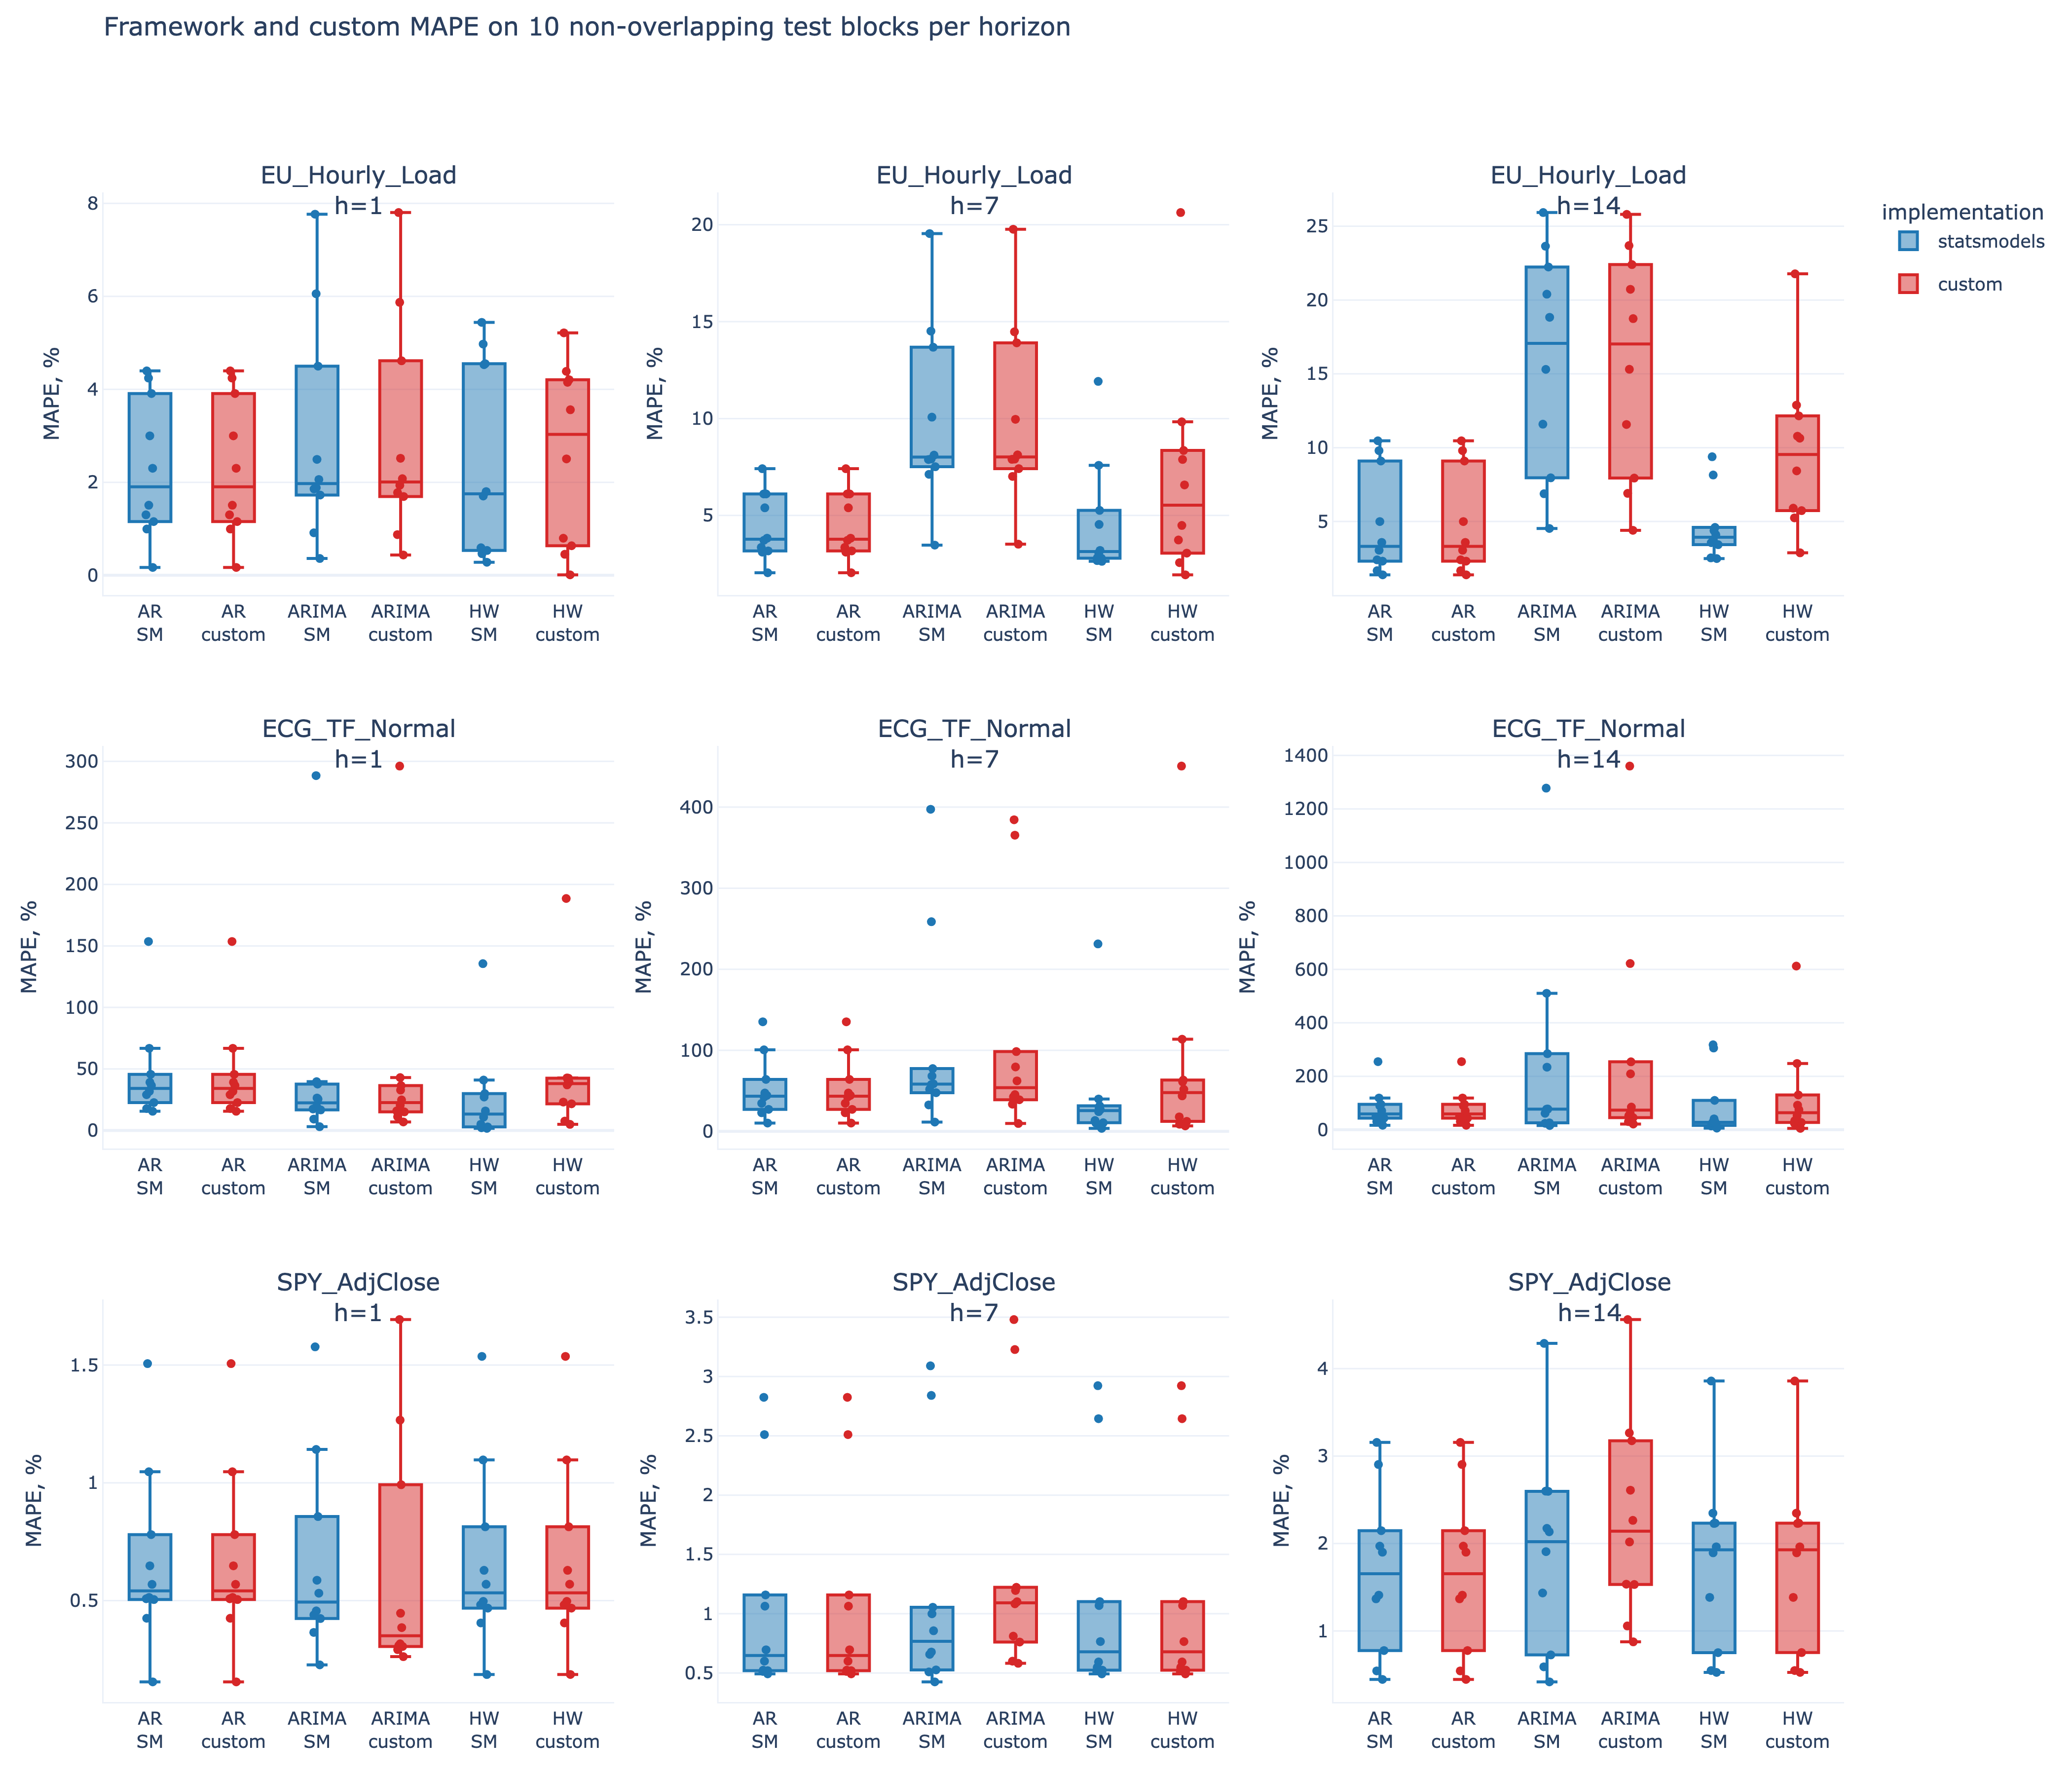

PosixPath('/Users/lopatenko/Desktop/itmo/itmo-ml-2025/tsml/lab-2/figures/mape_boxplots.png')

In [10]:
def show_and_save(fig: go.Figure, stem: str, height: int = 900) -> Path:
    fig.update_layout(
        template="plotly_white",
        width=FIG_WIDTH,
        height=height,
        margin=dict(l=70, r=30, t=130, b=50),
        title_y=0.99,
        title_yanchor="top",
    )
    fig.update_xaxes(showline=True)
    fig.update_yaxes(showline=True)
    path = FIGURES_DIR / f"{stem}.png"
    fig.write_image(str(path), scale=FIG_SCALE, width=FIG_WIDTH, height=height)
    fig.show(renderer="notebook_connected")
    display(Image(filename=str(path)))
    return path


def plot_mape_boxes(results: pd.DataFrame) -> go.Figure:
    series_names = [bundle.name for bundle in SERIES]
    colors = {"statsmodels": "#1f77b4", "custom": "#d62728"}
    fig = make_subplots(
        rows=3,
        cols=3,
        subplot_titles=[f"{series_name}<br>h={h}" for series_name in series_names for h in HORIZONS],
        vertical_spacing=0.10,
        horizontal_spacing=0.06,
    )
    for row, series_name in enumerate(series_names, start=1):
        for col, horizon in enumerate(HORIZONS, start=1):
            panel = results[(results["series"] == series_name) & (results["horizon"] == horizon)]
            short_name = {"AR": "AR", "ARIMA": "ARIMA", "Holt-Winters": "HW"}
            for family in FAMILIES:
                for implementation in IMPLEMENTATIONS:
                    model_data = panel[
                        (panel["family"] == family) & (panel["implementation"] == implementation)
                    ]
                    axis_label = f"{short_name[family]}<br>{'SM' if implementation == 'statsmodels' else 'custom'}"
                    fig.add_trace(
                        go.Box(
                            x=[axis_label] * len(model_data),
                            y=model_data["mape"],
                            name=implementation,
                            legendgroup=implementation,
                            showlegend=(row == 1 and col == 1 and family == "AR"),
                            boxpoints="all",
                            jitter=0.25,
                            pointpos=0,
                            marker_color=colors[implementation],
                            width=0.5,
                        ),
                        row=row,
                        col=col,
                    )
            fig.update_yaxes(title_text="MAPE, %", row=row, col=col)
    fig.update_layout(
        title="Framework and custom MAPE on 10 non-overlapping test blocks per horizon",
        boxmode="group",
        legend_title_text="implementation",
    )
    fig.update_annotations(yshift=-20)
    return fig


show_and_save(plot_mape_boxes(results), "mape_boxplots", height=1200)


Each series–horizon pair has its own axes. Every model family has a statsmodels box and a custom box computed with the same fixed structural hyperparameters. Percentage error on ECG can be orders of magnitude larger when the waveform crosses zero, so its within-panel ranking is more informative than a direct comparison with positive-valued load or prices.


## 7. Forecast disagreement between implementations


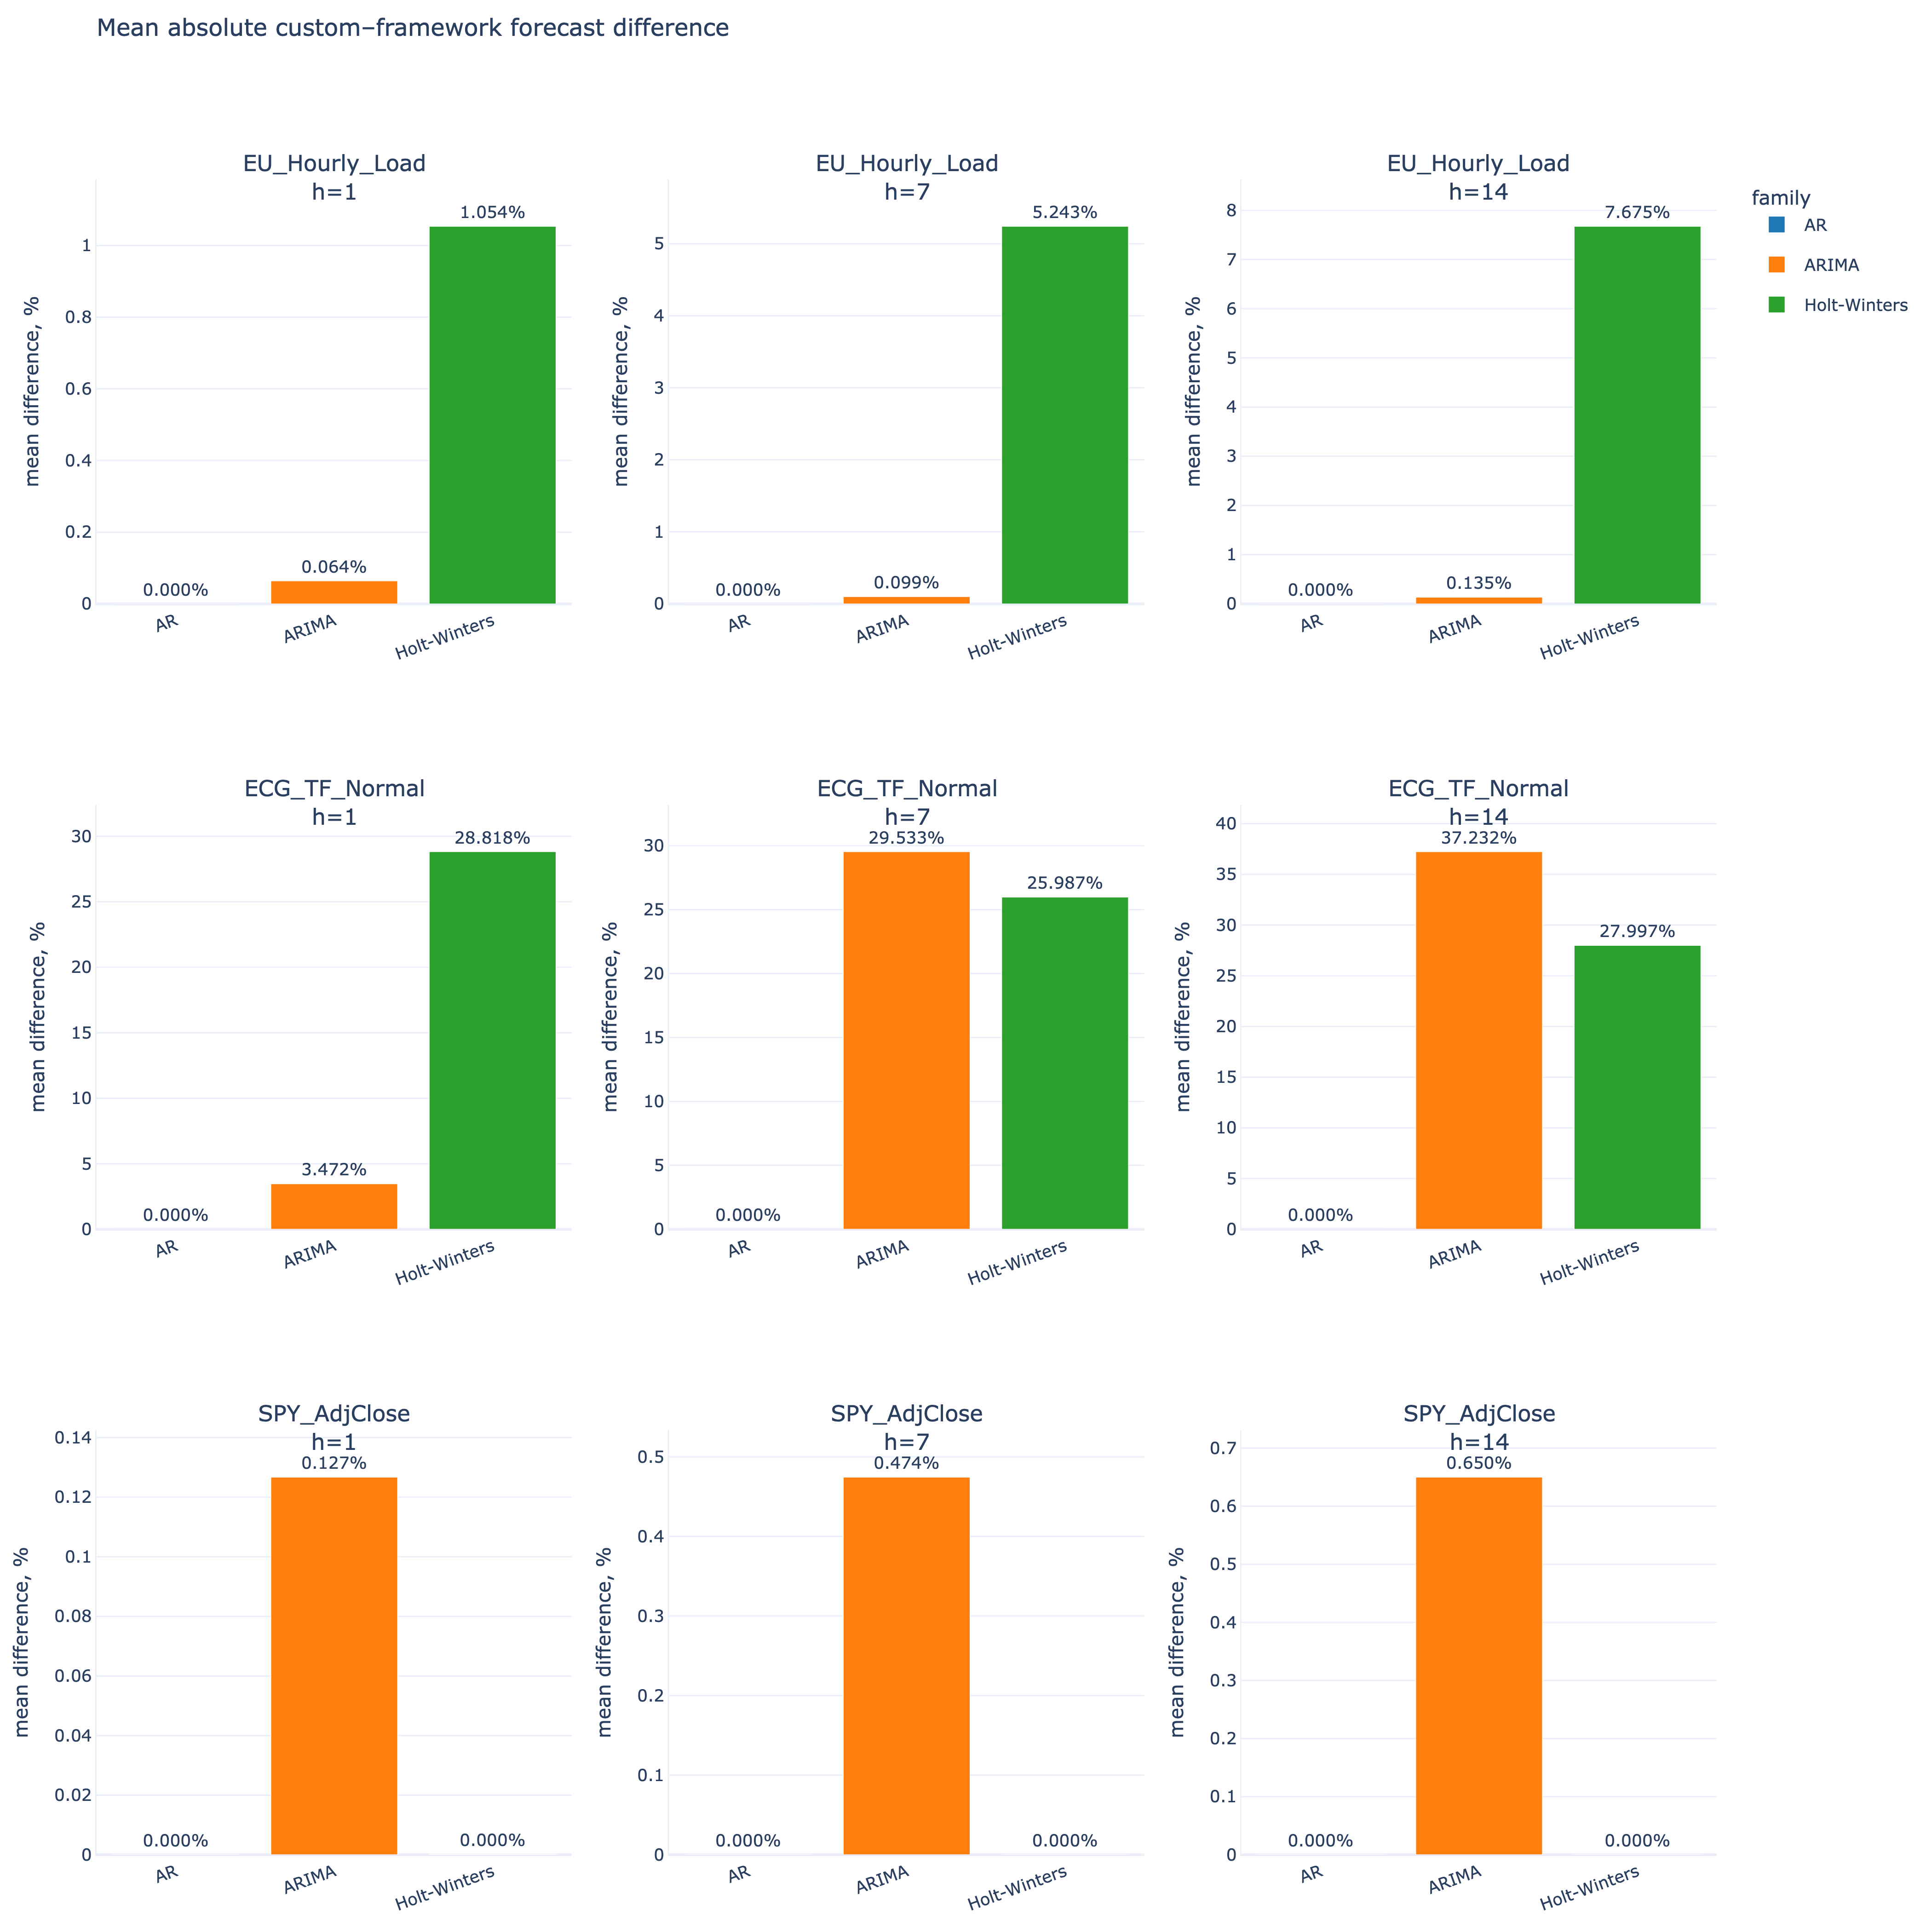

PosixPath('/Users/lopatenko/Desktop/itmo/itmo-ml-2025/tsml/lab-2/figures/framework_custom_difference.png')

In [11]:
def plot_forecast_difference(comparison: pd.DataFrame) -> go.Figure:
    series_names = [bundle.name for bundle in SERIES]
    colors = {"AR": "#1f77b4", "ARIMA": "#ff7f0e", "Holt-Winters": "#2ca02c"}
    fig = make_subplots(
        rows=3,
        cols=3,
        subplot_titles=[f"{series_name}<br>h={h}" for series_name in series_names for h in HORIZONS],
        vertical_spacing=0.12,
        horizontal_spacing=0.06,
    )
    for row, series_name in enumerate(series_names, start=1):
        for col, horizon in enumerate(HORIZONS, start=1):
            panel = comparison[(comparison["series"] == series_name) & (comparison["horizon"] == horizon)]
            for family in FAMILIES:
                value = panel.loc[panel["family"] == family, "mean_forecast_difference_pct"].iloc[0]
                fig.add_trace(
                    go.Bar(
                        x=[family],
                        y=[value],
                        name=family,
                        legendgroup=family,
                        showlegend=(row == 1 and col == 1),
                        marker_color=colors[family],
                        text=[f"{value:.3f}%"],
                        textposition="outside",
                    ),
                    row=row,
                    col=col,
                )
            fig.update_yaxes(title_text="mean difference, %", row=row, col=col)
            fig.update_xaxes(tickangle=-20, row=row, col=col)
    fig.update_layout(
        title="Mean absolute custom–framework forecast difference",
        legend_title_text="family",
        showlegend=True,
    )
    fig.update_annotations(yshift=-20)
    return fig


show_and_save(plot_forecast_difference(comparison), "framework_custom_difference", height=1400)


The disagreement metric is not an accuracy score: it measures how closely the custom recursion reproduces the framework forecast. A small value means that the two estimators produce nearly identical predictions under the shared model structure.


## 8. Example 14-step forecasts


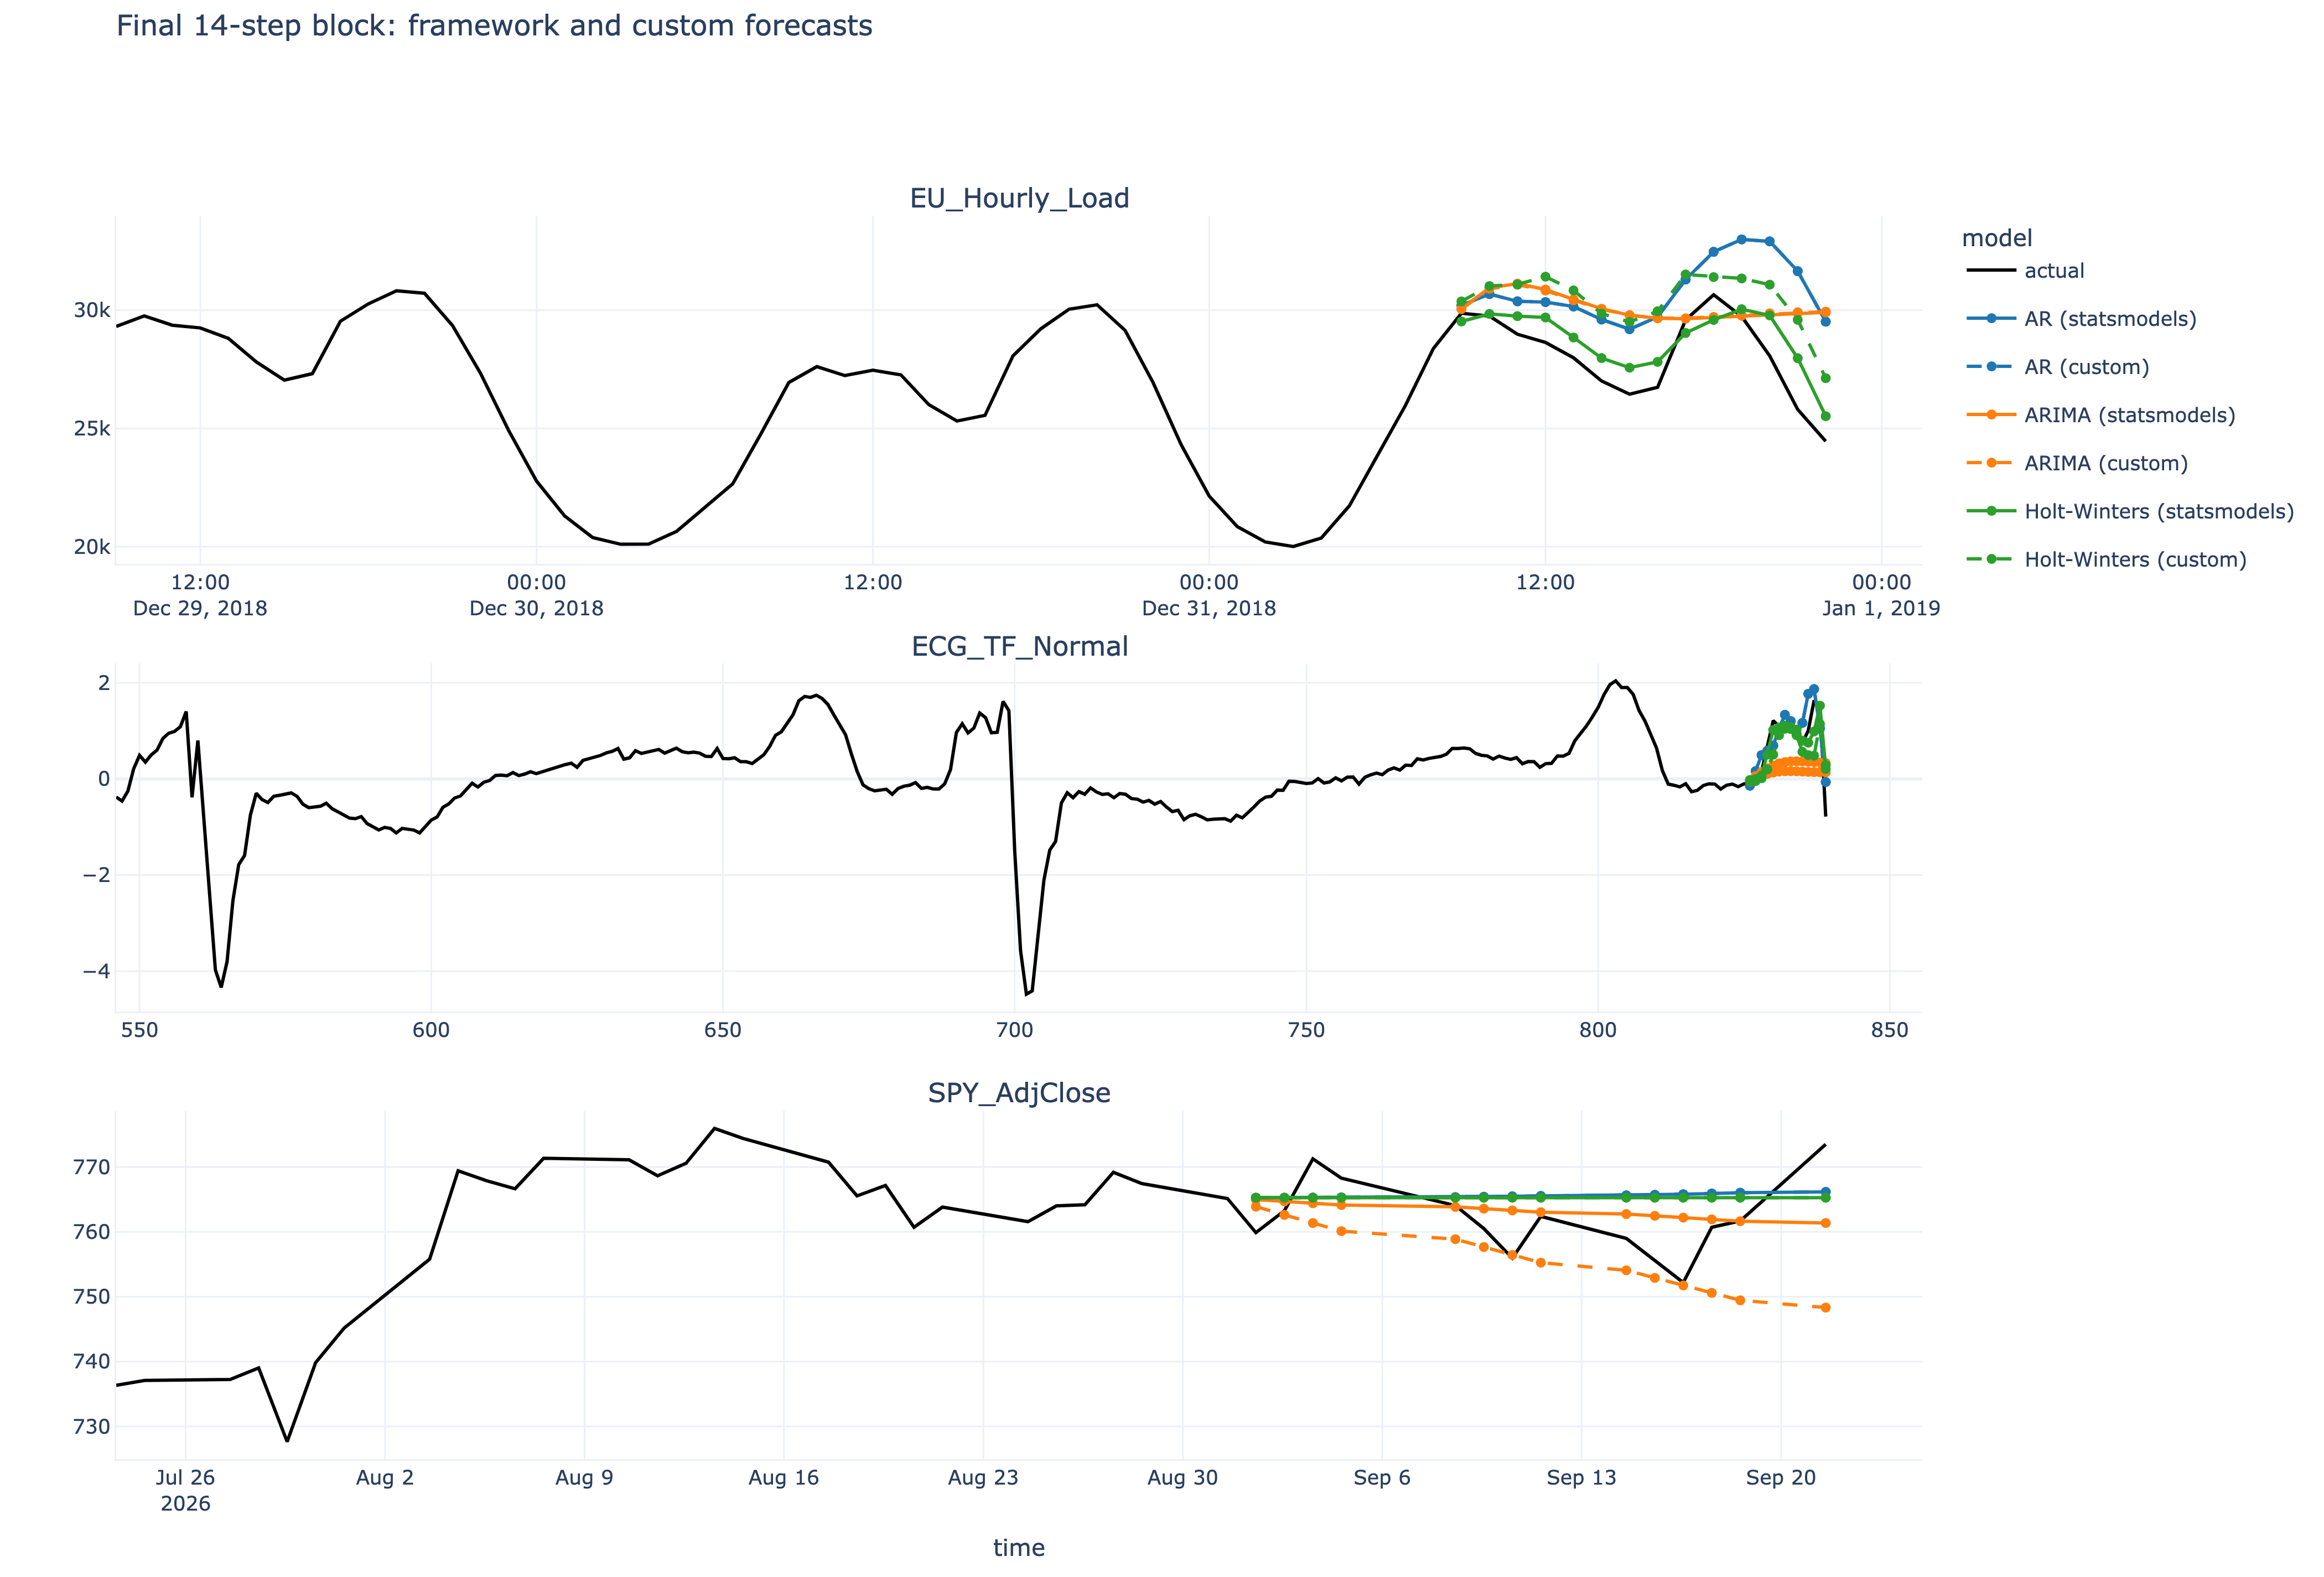

PosixPath('/Users/lopatenko/Desktop/itmo/itmo-ml-2025/tsml/lab-2/figures/forecast_examples.png')

In [12]:
def x_values(bundle: SeriesBundle, start: int, stop: int):
    if bundle.index is None:
        return np.arange(start, stop)
    return bundle.index[start:stop]


def plot_forecast_examples() -> go.Figure:
    fig = make_subplots(
        rows=3,
        cols=1,
        subplot_titles=[bundle.name for bundle in SERIES],
        vertical_spacing=0.08,
    )
    colors = {"AR": "#1f77b4", "ARIMA": "#ff7f0e", "Holt-Winters": "#2ca02c"}
    dashes = {"statsmodels": "solid", "custom": "dash"}
    horizon, split = 14, N_SPLITS
    for row, bundle in enumerate(SERIES, start=1):
        _, _, origin = FORECASTS[(bundle.name, "AR", "statsmodels", horizon, split)]
        context_start = max(0, origin - 2 * (bundle.seasonal_period or horizon))
        fig.add_trace(
            go.Scatter(
                x=x_values(bundle, context_start, origin + horizon),
                y=bundle.values[context_start:origin + horizon],
                mode="lines",
                name="actual",
                legendgroup="actual",
                showlegend=(row == 1),
                line=dict(color="black", width=2),
            ),
            row=row,
            col=1,
        )
        for family in FAMILIES:
            for implementation in IMPLEMENTATIONS:
                _, forecast, _ = FORECASTS[(bundle.name, family, implementation, horizon, split)]
                label = f"{family} ({implementation})"
                fig.add_trace(
                    go.Scatter(
                        x=x_values(bundle, origin, origin + horizon),
                        y=forecast,
                        mode="lines+markers",
                        name=label,
                        legendgroup=label,
                        showlegend=(row == 1),
                        line=dict(color=colors[family], dash=dashes[implementation], width=2),
                    ),
                    row=row,
                    col=1,
                )
    fig.update_layout(title="Final 14-step block: framework and custom forecasts", legend_title_text="model")
    fig.update_xaxes(title_text="time", row=3, col=1)
    return fig


show_and_save(plot_forecast_examples(), "forecast_examples", height=950)


## 9. Conclusions


In [13]:
def build_conclusion(summary: pd.DataFrame, comparison: pd.DataFrame) -> str:
    lines = ["### Observed results", ""]
    for bundle in SERIES:
        part = summary[summary["series"] == bundle.name]
        lines.append(f"#### {bundle.name}")
        for horizon in HORIZONS:
            ranked = part[part["horizon"] == horizon].sort_values("mean_mape")
            best = ranked.iloc[0]
            runner_up = ranked.iloc[1]
            best_name = f"{best['family']} ({best['implementation']})"
            runner_up_name = f"{runner_up['family']} ({runner_up['implementation']})"
            lines.append(
                f"- **h={horizon}:** {best_name} has the lowest mean MAPE "
                f"({best['mean_mape']:.3f}%; median {best['median_mape']:.3f}%). "
                f"The next model is {runner_up_name} ({runner_up['mean_mape']:.3f}%)."
            )
        lines.append("")

    ranked_summary = summary.assign(model=summary["family"] + " (" + summary["implementation"] + ")")
    winners = ranked_summary.loc[
        ranked_summary.groupby(["series", "horizon"])["mean_mape"].idxmin()
    ].groupby("model").size().sort_values(ascending=False)
    most_wins = winners.index[0]
    closest = comparison.loc[comparison["mean_forecast_difference_pct"].idxmin()]
    largest = comparison.loc[comparison["mean_forecast_difference_pct"].idxmax()]
    family_deltas = comparison.groupby("family")["mean_mape_delta"].mean()
    lines += [
        "### Custom versus statsmodels",
        "",
        f"- Closest forecasts: **{closest['series']}, {closest['family']}, h={int(closest['horizon'])}** "
        f"with {closest['mean_forecast_difference_pct']:.3f}% mean normalized disagreement.",
        f"- Largest disagreement: **{largest['series']}, {largest['family']}, h={int(largest['horizon'])}** "
        f"with {largest['mean_forecast_difference_pct']:.3f}%.",
        "- Average custom-minus-framework mean MAPE by family: "
        + ", ".join(f"{family} {delta:+.3f} pp" for family, delta in family_deltas.items()) + ".",
        "- The comparison uses one fixed structural configuration per series and family; differences therefore come from estimation, initialization and recursion details, not different orders or seasonal periods.",
        "",
        "### Overall interpretation",
        "",
        f"- **{most_wins}** wins the largest number of series–horizon combinations "
        f"({int(winners.iloc[0])} of {len(SERIES) * len(HORIZONS)}).",
        "- Horizon effects are data-dependent: compare both the median and box width. A low median with a wide box means that the model works on typical blocks but is unreliable around regime changes or unusual waveform segments.",
        "- Load rewards models that reuse its daily structure. ECG rewards beat-scale memory when morphology is stable, but conventional MAPE is intrinsically volatile near zero crossings. SPY is dominated by local persistence; extra model complexity cannot create dependable return predictability.",
        "- These conclusions apply to the selected samples and rolling origins. The protocol estimates interpolation-like short-horizon performance, not robustness to a future structural break.",
    ]
    return "\n".join(lines)


CONCLUSION_MD = build_conclusion(summary, comparison)
display(Markdown(CONCLUSION_MD))


### Observed results

#### EU_Hourly_Load
- **h=1:** AR (custom) has the lowest mean MAPE (2.298%; median 1.904%). The next model is AR (statsmodels) (2.298%).
- **h=7:** AR (statsmodels) has the lowest mean MAPE (4.424%; median 3.772%). The next model is AR (custom) (4.424%).
- **h=14:** Holt-Winters (statsmodels) has the lowest mean MAPE (4.636%; median 3.927%). The next model is AR (statsmodels) (4.873%).

#### ECG_TF_Normal
- **h=1:** Holt-Winters (statsmodels) has the lowest mean MAPE (27.222%; median 13.360%). The next model is Holt-Winters (custom) (44.920%).
- **h=7:** Holt-Winters (statsmodels) has the lowest mean MAPE (41.996%; median 25.508%). The next model is AR (custom) (52.856%).
- **h=14:** AR (statsmodels) has the lowest mean MAPE (81.555%; median 59.239%). The next model is AR (custom) (81.555%).

#### SPY_AdjClose
- **h=1:** ARIMA (custom) has the lowest mean MAPE (0.627%; median 0.351%). The next model is ARIMA (statsmodels) (0.661%).
- **h=7:** AR (custom) has the lowest mean MAPE (1.091%; median 0.648%). The next model is AR (statsmodels) (1.091%).
- **h=14:** AR (statsmodels) has the lowest mean MAPE (1.662%; median 1.655%). The next model is AR (custom) (1.662%).

### Custom versus statsmodels

- Closest forecasts: **SPY_AdjClose, AR, h=1** with 0.000% mean normalized disagreement.
- Largest disagreement: **ECG_TF_Normal, ARIMA, h=14** with 37.232%.
- Average custom-minus-framework mean MAPE by family: AR +0.000 pp, ARIMA +3.073 pp, Holt-Winters +11.866 pp.
- The comparison uses one fixed structural configuration per series and family; differences therefore come from estimation, initialization and recursion details, not different orders or seasonal periods.

### Overall interpretation

- **AR (statsmodels)** wins the largest number of series–horizon combinations (3 of 9).
- Horizon effects are data-dependent: compare both the median and box width. A low median with a wide box means that the model works on typical blocks but is unreliable around regime changes or unusual waveform segments.
- Load rewards models that reuse its daily structure. ECG rewards beat-scale memory when morphology is stable, but conventional MAPE is intrinsically volatile near zero crossings. SPY is dominated by local persistence; extra model complexity cannot create dependable return predictability.
- These conclusions apply to the selected samples and rolling origins. The protocol estimates interpolation-like short-horizon performance, not robustness to a future structural break.